**EDA**

In [58]:
print("Loan Default Prediction Project Started!")

Loan Default Prediction Project Started!


In [59]:
import pandas as pd
df = pd.read_csv("../DATA/application_train.csv")
print("Dataset loaded successfully!")

Dataset loaded successfully!


In [60]:
df.shape

(307511, 122)

In [61]:
df.columns

Index(['SK_ID_CURR', 'TARGET', 'NAME_CONTRACT_TYPE', 'CODE_GENDER',
       'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'CNT_CHILDREN', 'AMT_INCOME_TOTAL',
       'AMT_CREDIT', 'AMT_ANNUITY',
       ...
       'FLAG_DOCUMENT_18', 'FLAG_DOCUMENT_19', 'FLAG_DOCUMENT_20',
       'FLAG_DOCUMENT_21', 'AMT_REQ_CREDIT_BUREAU_HOUR',
       'AMT_REQ_CREDIT_BUREAU_DAY', 'AMT_REQ_CREDIT_BUREAU_WEEK',
       'AMT_REQ_CREDIT_BUREAU_MON', 'AMT_REQ_CREDIT_BUREAU_QRT',
       'AMT_REQ_CREDIT_BUREAU_YEAR'],
      dtype='object', length=122)

In [62]:
df.head()

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


In [63]:
df["TARGET"].value_counts()

TARGET
0    282686
1     24825
Name: count, dtype: int64

In [64]:
df["TARGET"].value_counts(normalize=True) * 100

TARGET
0    91.927118
1     8.072882
Name: proportion, dtype: float64

In [65]:
df.isnull().sum()

SK_ID_CURR                        0
TARGET                            0
NAME_CONTRACT_TYPE                0
CODE_GENDER                       0
FLAG_OWN_CAR                      0
                              ...  
AMT_REQ_CREDIT_BUREAU_DAY     41519
AMT_REQ_CREDIT_BUREAU_WEEK    41519
AMT_REQ_CREDIT_BUREAU_MON     41519
AMT_REQ_CREDIT_BUREAU_QRT     41519
AMT_REQ_CREDIT_BUREAU_YEAR    41519
Length: 122, dtype: int64

In [66]:
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
missing

COMMONAREA_MEDI             214865
COMMONAREA_AVG              214865
COMMONAREA_MODE             214865
NONLIVINGAPARTMENTS_MEDI    213514
NONLIVINGAPARTMENTS_MODE    213514
                             ...  
EXT_SOURCE_2                   660
AMT_GOODS_PRICE                278
AMT_ANNUITY                     12
CNT_FAM_MEMBERS                  2
DAYS_LAST_PHONE_CHANGE           1
Length: 67, dtype: int64

In [67]:
missing_percent = (df.isnull().sum() / len(df)) * 100
missing_percent = missing_percent[missing_percent > 0].sort_values(ascending=False)
missing_percent

COMMONAREA_MEDI             69.872297
COMMONAREA_AVG              69.872297
COMMONAREA_MODE             69.872297
NONLIVINGAPARTMENTS_MEDI    69.432963
NONLIVINGAPARTMENTS_MODE    69.432963
                              ...    
EXT_SOURCE_2                 0.214626
AMT_GOODS_PRICE              0.090403
AMT_ANNUITY                  0.003902
CNT_FAM_MEMBERS              0.000650
DAYS_LAST_PHONE_CHANGE       0.000325
Length: 67, dtype: float64

In [68]:
missing_percent = (df.isnull().sum() / len(df)) * 100
missing_percent[missing_percent > 50].sort_values(ascending=False)

COMMONAREA_AVG              69.872297
COMMONAREA_MEDI             69.872297
COMMONAREA_MODE             69.872297
NONLIVINGAPARTMENTS_MEDI    69.432963
NONLIVINGAPARTMENTS_AVG     69.432963
NONLIVINGAPARTMENTS_MODE    69.432963
FONDKAPREMONT_MODE          68.386172
LIVINGAPARTMENTS_MEDI       68.354953
LIVINGAPARTMENTS_AVG        68.354953
LIVINGAPARTMENTS_MODE       68.354953
FLOORSMIN_MODE              67.848630
FLOORSMIN_MEDI              67.848630
FLOORSMIN_AVG               67.848630
YEARS_BUILD_MODE            66.497784
YEARS_BUILD_AVG             66.497784
YEARS_BUILD_MEDI            66.497784
OWN_CAR_AGE                 65.990810
LANDAREA_AVG                59.376738
LANDAREA_MEDI               59.376738
LANDAREA_MODE               59.376738
BASEMENTAREA_MEDI           58.515956
BASEMENTAREA_AVG            58.515956
BASEMENTAREA_MODE           58.515956
EXT_SOURCE_1                56.381073
NONLIVINGAREA_MODE          55.179164
NONLIVINGAREA_MEDI          55.179164
NONLIVINGARE

In [69]:
df.dtypes.value_counts()

float64    65
int64      41
object     16
Name: count, dtype: int64

In [70]:
df.duplicated().sum()

np.int64(0)

In [71]:
df.describe()

,SK_ID_CURR,TARGET,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
count,307511.000000,307511.000000,307511.000000,3.075110e+05,3.075110e+05,307499.000000,3.072330e+05,307511.000000,307511.000000,307511.000000,...,307511.000000,307511.000000,307511.000000,307511.000000,265992.000000,265992.000000,265992.000000,265992.000000,265992.000000,265992.000000
mean,278180.518577,0.080729,0.417052,1.687979e+05,5.990260e+05,27108.573909,5.383962e+05,0.020868,-16036.995067,63815.045904,...,0.008130,0.000595,0.000507,0.000335,0.006402,0.007000,0.034362,0.267395,0.265474,1.899974
std,102790.175348,0.272419,0.722121,2.371231e+05,4.024908e+05,14493.737315,3.694465e+05,0.013831,4363.988632,141275.766519,...,0.089798,0.024387,0.022518,0.018299,0.083849,0.110757,0.204685,0.916002,0.794056,1.869295
min,100002.000000,0.000000,0.000000,2.565000e+04,4.500000e+04,1615.500000,4.050000e+04,0.000290,-25229.000000,-17912.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,189145.500000,0.000000,0.000000,1.125000e+05,2.700000e+05,16524.000000,2.385000e+05,0.010006,-19682.000000,-2760.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,278202.000000,0.000000,0.000000,1.471500e+05,5.135310e+05,24903.000000,4.500000e+05,0.018850,-15750.000000,-1213.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
75%,367142.500000,0.000000,1.000000,2.025000e+05,8.086500e+05,34596.000000,6.795000e+05,0.028663,-12413.000000,-289.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.000000
max,456255.000000,1.000000,19.000000,1.170000e+08,4.050000e+06,258025.500000,4.050000e+06,0.072508,-7489.000000,365243.000000,...,1.000000,1.000000,1.000000,1.000000,4.000000,9.000000,8.000000,27.000000,261.000000,25.000000


In [72]:
print("Numeric columns:", df.select_dtypes(include="number").shape[1])
print("Categorical columns:", df.select_dtypes(include="object").shape[1])
print("\nCategorical columns:")
print(df.select_dtypes(include="object").columns.tolist())

Numeric columns: 106
Categorical columns: 16

Categorical columns:
['NAME_CONTRACT_TYPE', 'CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'NAME_TYPE_SUITE', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE', 'WEEKDAY_APPR_PROCESS_START', 'ORGANIZATION_TYPE', 'FONDKAPREMONT_MODE', 'HOUSETYPE_MODE', 'WALLSMATERIAL_MODE', 'EMERGENCYSTATE_MODE']


In [73]:
# Average values of numerical features for each target class
numeric_cols = df.select_dtypes(include="number").columns
target_means = df.groupby("TARGET")[numeric_cols].mean().T
target_means.head(20)

TARGET,0,1
SK_ID_CURR,278244.744536,277449.167936
TARGET,0.000000,1.000000
CNT_CHILDREN,0.412946,0.463807
AMT_INCOME_TOTAL,169077.722266,165611.760906
AMT_CREDIT,602648.282002,557778.527674
AMT_ANNUITY,27163.623349,26481.744290
AMT_GOODS_PRICE,542736.795003,488972.412554
REGION_POPULATION_RELATIVE,0.021021,0.019131
DAYS_BIRTH,-16138.176397,-14884.828077
DAYS_EMPLOYED,65696.146123,42394.675448


In [74]:
default_by_contract = pd.crosstab(
    df["NAME_CONTRACT_TYPE"],
    df["TARGET"],
    normalize="index"
) * 100
default_by_contract

TARGET,0,1
NAME_CONTRACT_TYPE,,
Cash loans,91.654087,8.345913
Revolving loans,94.521671,5.478329


In [75]:
default_by_contract = pd.crosstab(
    df["NAME_CONTRACT_TYPE"],
    df["TARGET"],
    normalize="index"
) * 100
default_by_contract

TARGET,0,1
NAME_CONTRACT_TYPE,,
Cash loans,91.654087,8.345913
Revolving loans,94.521671,5.478329


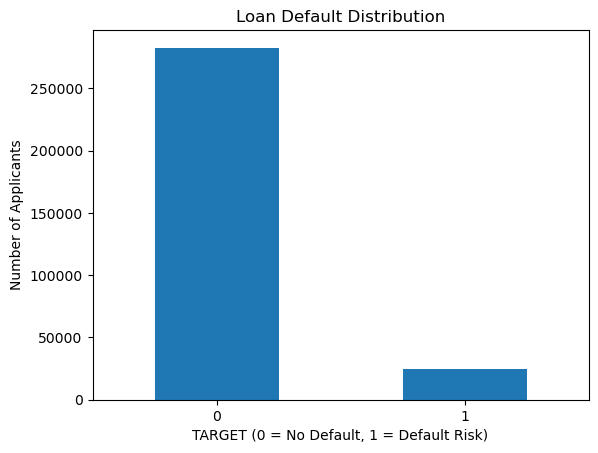

In [76]:
import matplotlib.pyplot as plt
df["TARGET"].value_counts().plot(kind="bar")
plt.title("Loan Default Distribution")
plt.xlabel("TARGET (0 = No Default, 1 = Default Risk)")
plt.ylabel("Number of Applicants")
plt.xticks(rotation=0)
plt.show()

In [77]:
correlation = df.select_dtypes(include="number").corr()["TARGET"]
top_correlations = correlation.drop("TARGET").abs().sort_values(ascending=False).head(10)
top_correlations

EXT_SOURCE_3                   0.178919
EXT_SOURCE_2                   0.160472
EXT_SOURCE_1                   0.155317
DAYS_BIRTH                     0.078239
REGION_RATING_CLIENT_W_CITY    0.060893
REGION_RATING_CLIENT           0.058899
DAYS_LAST_PHONE_CHANGE         0.055218
DAYS_ID_PUBLISH                0.051457
REG_CITY_NOT_WORK_CITY         0.050994
FLAG_EMP_PHONE                 0.045982
Name: TARGET, dtype: float64

In [78]:
# Top 10 features most strongly correlated with TARGET
top_features = (
    df.select_dtypes(include="number")
      .corr()["TARGET"]
      .drop("TARGET")
      .abs()
      .sort_values(ascending=False)
      .head(10)
)
top_features

EXT_SOURCE_3                   0.178919
EXT_SOURCE_2                   0.160472
EXT_SOURCE_1                   0.155317
DAYS_BIRTH                     0.078239
REGION_RATING_CLIENT_W_CITY    0.060893
REGION_RATING_CLIENT           0.058899
DAYS_LAST_PHONE_CHANGE         0.055218
DAYS_ID_PUBLISH                0.051457
REG_CITY_NOT_WORK_CITY         0.050994
FLAG_EMP_PHONE                 0.045982
Name: TARGET, dtype: float64

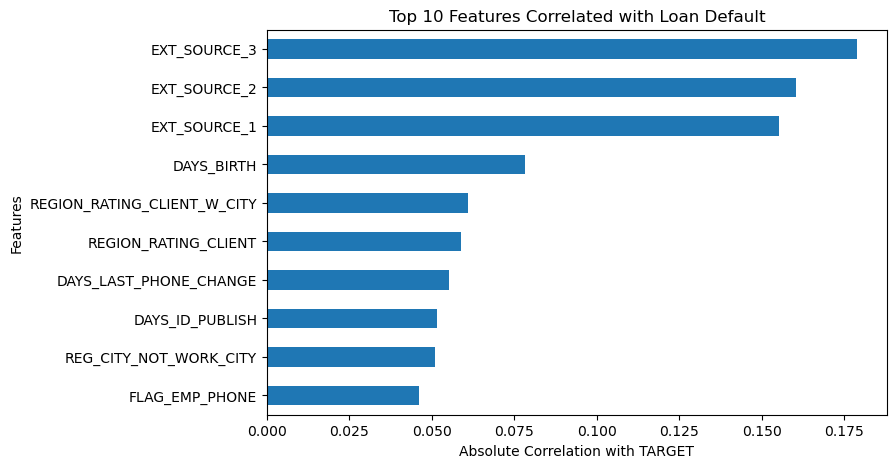

In [79]:
top_features.sort_values().plot(kind="barh", figsize=(8, 5))
plt.title("Top 10 Features Correlated with Loan Default")
plt.xlabel("Absolute Correlation with TARGET")
plt.ylabel("Features")
plt.show()

In [80]:
important_features = top_features.index.tolist()
df[important_features].describe().T

,count,mean,std,min,25%,50%,75%,max
EXT_SOURCE_3,246546.0,0.510853,0.194844,5.272652e-04,0.370650,0.535276,0.669057,0.896010
EXT_SOURCE_2,306851.0,0.514393,0.191060,8.173617e-08,0.392457,0.565961,0.663617,0.855000
EXT_SOURCE_1,134133.0,0.502130,0.211062,1.456813e-02,0.334007,0.505998,0.675053,0.962693
DAYS_BIRTH,307511.0,-16036.995067,4363.988632,-2.522900e+04,-19682.000000,-15750.000000,-12413.000000,-7489.000000
REGION_RATING_CLIENT_W_CITY,307511.0,2.031521,0.502737,1.000000e+00,2.000000,2.000000,2.000000,3.000000
REGION_RATING_CLIENT,307511.0,2.052463,0.509034,1.000000e+00,2.000000,2.000000,2.000000,3.000000
DAYS_LAST_PHONE_CHANGE,307510.0,-962.858788,826.808487,-4.292000e+03,-1570.000000,-757.000000,-274.000000,0.000000
DAYS_ID_PUBLISH,307511.0,-2994.202373,1509.450419,-7.197000e+03,-4299.000000,-3254.000000,-1720.000000,0.000000
REG_CITY_NOT_WORK_CITY,307511.0,0.230454,0.421124,0.000000e+00,0.000000,0.000000,0.000000,1.000000
FLAG_EMP_PHONE,307511.0,0.819889,0.384280,0.000000e+00,1.000000,1.000000,1.000000,1.000000


In [81]:
constant_columns = [
    col for col in df.columns
    if df[col].nunique(dropna=False) <= 1
]
print("Number of constant columns:", len(constant_columns))
print("Constant columns:", constant_columns)

Number of constant columns: 0
Constant columns: []


**Preprocessing**

In [82]:
X = df.drop("TARGET", axis=1)
y = df["TARGET"]
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (307511, 121)
y shape: (307511,)


In [83]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (246008, 121)
X_test: (61503, 121)
y_train: (246008,)
y_test: (61503,)


In [84]:
categorical_cols = X_train.select_dtypes(include="object").columns.tolist()
numeric_cols = X_train.select_dtypes(exclude="object").columns.tolist()
print("Categorical columns:", len(categorical_cols))
print("Numeric columns:", len(numeric_cols))

Categorical columns: 16
Numeric columns: 105


In [85]:
missing_ratio = X_train.isnull().mean()
high_missing_cols = missing_ratio[missing_ratio > 0.50].index.tolist()
print("Columns to remove:", len(high_missing_cols))
print(high_missing_cols)

Columns to remove: 41
['OWN_CAR_AGE', 'EXT_SOURCE_1', 'APARTMENTS_AVG', 'BASEMENTAREA_AVG', 'YEARS_BUILD_AVG', 'COMMONAREA_AVG', 'ELEVATORS_AVG', 'ENTRANCES_AVG', 'FLOORSMIN_AVG', 'LANDAREA_AVG', 'LIVINGAPARTMENTS_AVG', 'LIVINGAREA_AVG', 'NONLIVINGAPARTMENTS_AVG', 'NONLIVINGAREA_AVG', 'APARTMENTS_MODE', 'BASEMENTAREA_MODE', 'YEARS_BUILD_MODE', 'COMMONAREA_MODE', 'ELEVATORS_MODE', 'ENTRANCES_MODE', 'FLOORSMIN_MODE', 'LANDAREA_MODE', 'LIVINGAPARTMENTS_MODE', 'LIVINGAREA_MODE', 'NONLIVINGAPARTMENTS_MODE', 'NONLIVINGAREA_MODE', 'APARTMENTS_MEDI', 'BASEMENTAREA_MEDI', 'YEARS_BUILD_MEDI', 'COMMONAREA_MEDI', 'ELEVATORS_MEDI', 'ENTRANCES_MEDI', 'FLOORSMIN_MEDI', 'LANDAREA_MEDI', 'LIVINGAPARTMENTS_MEDI', 'LIVINGAREA_MEDI', 'NONLIVINGAPARTMENTS_MEDI', 'NONLIVINGAREA_MEDI', 'FONDKAPREMONT_MODE', 'HOUSETYPE_MODE', 'WALLSMATERIAL_MODE']


In [86]:
X_train = X_train.drop(columns=high_missing_cols)
X_test = X_test.drop(columns=high_missing_cols)
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

X_train shape: (246008, 80)
X_test shape: (61503, 80)


In [87]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
categorical_cols = X_train.select_dtypes(include="object").columns.tolist()
numeric_cols = X_train.select_dtypes(exclude="object").columns.tolist()
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_cols),
    ("categorical", categorical_pipeline, categorical_cols)
])
print("Numeric columns:", len(numeric_cols))
print("Categorical columns:", len(categorical_cols))
print("Preprocessor created successfully!")

Numeric columns: 67
Categorical columns: 13
Preprocessor created successfully!


In [88]:
print("Training target distribution:")
print(y_train.value_counts())
print("\nTraining target percentage:")
print((y_train.value_counts(normalize=True) * 100).round(2))

Training target distribution:
TARGET
0    226148
1     19860
Name: count, dtype: int64

Training target percentage:
TARGET
0    91.93
1     8.07
Name: proportion, dtype: float64


In [89]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
print("Logistic Regression imports ready!")

Logistic Regression imports ready!


In [90]:
logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])
print("Logistic Regression pipeline updated!")

Logistic Regression pipeline updated!


In [91]:
print("Training Logistic Regression...")
logistic_model.fit(X_train, y_train)
print("Logistic Regression trained successfully!")

Training Logistic Regression...
Logistic Regression trained successfully!


c:\Users\welcome\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 2000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=2000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [92]:
from sklearn.metrics import roc_auc_score
y_pred_proba = logistic_model.predict_proba(X_test)[:, 1]
logistic_auc = roc_auc_score(y_test, y_pred_proba)
print("Logistic Regression ROC-AUC:", round(logistic_auc, 4))

Logistic Regression ROC-AUC: 0.6313


In [93]:
from sklearn.metrics import confusion_matrix, classification_report
y_pred = logistic_model.predict(X_test)
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
print(cm)
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Confusion Matrix:
[[33114 23424]
 [ 1934  3031]]

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.59      0.72     56538
           1       0.11      0.61      0.19      4965

    accuracy                           0.59     61503
   macro avg       0.53      0.60      0.46     61503
weighted avg       0.88      0.59      0.68     61503



In [94]:
from sklearn.ensemble import RandomForestClassifier
random_forest_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=200,
        max_depth=12,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])
print("Random Forest pipeline created successfully!")

Random Forest pipeline created successfully!


In [95]:
print("Training Random Forest...")
random_forest_model.fit(X_train, y_train)
print("Random Forest trained successfully!")

Training Random Forest...
Random Forest trained successfully!


In [96]:
from sklearn.metrics import roc_auc_score
rf_pred_proba = random_forest_model.predict_proba(X_test)[:, 1]
rf_auc = roc_auc_score(y_test, rf_pred_proba)
print("Random Forest ROC-AUC:", round(rf_auc, 4))

Random Forest ROC-AUC: 0.7349


In [97]:
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.


In [98]:
import xgboost as xgb
print("XGBoost version:", xgb.__version__)

XGBoost version: 3.4.1


In [99]:
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
xgb_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", XGBClassifier(
        n_estimators=200,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="binary:logistic",
        eval_metric="auc",
        random_state=42,
        n_jobs=-1
    ))
])
print("XGBoost pipeline created successfully!")

XGBoost pipeline created successfully!


In [100]:
print("Training XGBoost...")
xgb_model.fit(X_train, y_train)
print("XGBoost trained successfully!")

Training XGBoost...
XGBoost trained successfully!


In [101]:
from sklearn.metrics import roc_auc_score
xgb_pred_proba = xgb_model.predict_proba(X_test)[:, 1]
xgb_auc = roc_auc_score(y_test, xgb_pred_proba)
print("XGBoost ROC-AUC:", round(xgb_auc, 4))

XGBoost ROC-AUC: 0.7555


In [102]:
import pandas as pd
model_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "XGBoost"
    ],
    "ROC-AUC": [
        logistic_auc,
        rf_auc,
        xgb_auc
    ]
})
model_results

,Model,ROC-AUC
0,Logistic Regression,0.631307
1,Random Forest,0.734920
2,XGBoost,0.755497


In [103]:
model_results.sort_values("ROC-AUC", ascending=False)

,Model,ROC-AUC
2,XGBoost,0.755497
1,Random Forest,0.734920
0,Logistic Regression,0.631307


In [104]:
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
xgb_tuned = Pipeline([
    ("preprocessor", preprocessor),
    ("model", XGBClassifier(
        n_estimators=400,
        max_depth=4,
        learning_rate=0.05,
        min_child_weight=5,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=11.39,
        objective="binary:logistic",
        eval_metric="auc",
        random_state=42,
        n_jobs=-1
    ))
])
print("Tuned XGBoost pipeline created!")

Tuned XGBoost pipeline created!


In [105]:
print("Training tuned XGBoost...")
xgb_tuned.fit(X_train, y_train)
print("Tuned XGBoost trained successfully!")

Training tuned XGBoost...
Tuned XGBoost trained successfully!


In [106]:
from sklearn.metrics import roc_auc_score
xgb_tuned_pred_proba = xgb_tuned.predict_proba(X_test)[:, 1]
xgb_tuned_auc = roc_auc_score(
    y_test,
    xgb_tuned_pred_proba
)
print("Tuned XGBoost ROC-AUC:", round(xgb_tuned_auc, 4))

Tuned XGBoost ROC-AUC: 0.7564


In [107]:
model_results_final = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "XGBoost",
        "Tuned XGBoost"
    ],
    "ROC-AUC": [
        logistic_auc,
        rf_auc,
        xgb_auc,
        xgb_tuned_auc
    ]
})
model_results_final = model_results_final.sort_values(
    "ROC-AUC",
    ascending=False
).reset_index(drop=True)
model_results_final

,Model,ROC-AUC
0,Tuned XGBoost,0.756396
1,XGBoost,0.755497
2,Random Forest,0.734920
3,Logistic Regression,0.631307


In [108]:
print("Best measured model:", model_results_final.loc[0, "Model"])
print("Best ROC-AUC:", round(model_results_final.loc[0, "ROC-AUC"], 4))

Best measured model: Tuned XGBoost
Best ROC-AUC: 0.7564


In [109]:
best_model_name = model_results_final.loc[0, "Model"]
if best_model_name == "Logistic Regression":
    final_model = logistic_model
    final_pred_proba = logistic_model.predict_proba(X_test)[:, 1]
elif best_model_name == "Random Forest":
    final_model = random_forest_model
    final_pred_proba = random_forest_model.predict_proba(X_test)[:, 1]
elif best_model_name == "XGBoost":
    final_model = xgb_model
    final_pred_proba = xgb_model.predict_proba(X_test)[:, 1]
else:
    final_model = xgb_tuned
    final_pred_proba = xgb_tuned.predict_proba(X_test)[:, 1]
print("Final model:", best_model_name)

Final model: Tuned XGBoost


              precision    recall  f1-score   support

           0       0.96      0.70      0.81     56538
           1       0.17      0.67      0.27      4965

    accuracy                           0.70     61503
   macro avg       0.56      0.69      0.54     61503
weighted avg       0.90      0.70      0.77     61503



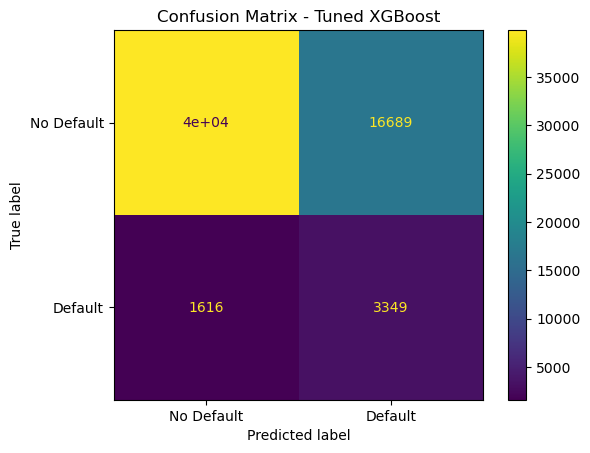

In [110]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
final_pred = (final_pred_proba >= 0.5).astype(int)
print(classification_report(y_test, final_pred))
cm = confusion_matrix(y_test, final_pred)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Default", "Default"]
)
disp.plot()
plt.title(f"Confusion Matrix - {best_model_name}")
plt.show()

In [111]:
from sklearn.metrics import precision_score, recall_score, f1_score
thresholds = [0.20, 0.30, 0.40, 0.50, 0.60]
threshold_results = []
for threshold in thresholds:
    predictions = (final_pred_proba >= threshold).astype(int)
    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1-Score": f1_score(y_test, predictions, zero_division=0)
    })
threshold_results = pd.DataFrame(threshold_results)
threshold_results

,Threshold,Precision,Recall,F1-Score
0,0.2,0.093003,0.968379,0.169708
1,0.3,0.111767,0.907956,0.199033
2,0.4,0.135387,0.806244,0.231843
3,0.5,0.167132,0.674522,0.267888
4,0.6,0.209285,0.516616,0.297892


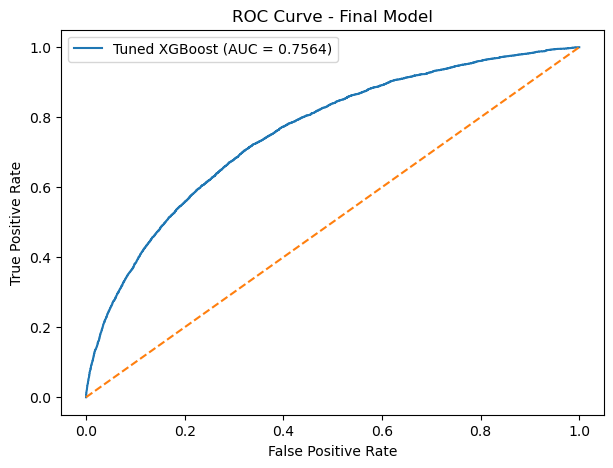

In [112]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt
fpr, tpr, thresholds_roc = roc_curve(
    y_test,
    final_pred_proba
)
roc_auc = auc(fpr, tpr)
plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"{best_model_name} (AUC = {roc_auc:.4f})")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Final Model")
plt.legend()
plt.show()

In [113]:
%pip install shap

Note: you may need to restart the kernel to use updated packages.


In [114]:
import shap
print("SHAP version:", shap.__version__)

SHAP version: 0.52.0


In [115]:
# Get the trained preprocessing step
preprocessor_fitted = xgb_tuned.named_steps["preprocessor"]
# Transform a sample of test data
X_shap_sample = X_test.sample(
    n=min(2000, len(X_test)),
    random_state=42
)
X_shap_transformed = preprocessor_fitted.transform(X_shap_sample)
# Get the trained XGBoost model
xgb_final_model = xgb_tuned.named_steps["model"]
print("SHAP sample shape:", X_shap_transformed.shape)
print("SHAP data prepared successfully!")

SHAP sample shape: (2000, 193)
SHAP data prepared successfully!


In [116]:
explainer = shap.TreeExplainer(xgb_final_model)
shap_values = explainer(X_shap_transformed)
print("SHAP values calculated successfully!")
print("SHAP shape:", shap_values.values.shape)

SHAP values calculated successfully!
SHAP shape: (2000, 193)


In [117]:
# Get feature names after preprocessing
feature_names = preprocessor_fitted.get_feature_names_out()
print("Number of features:", len(feature_names))

Number of features: 193


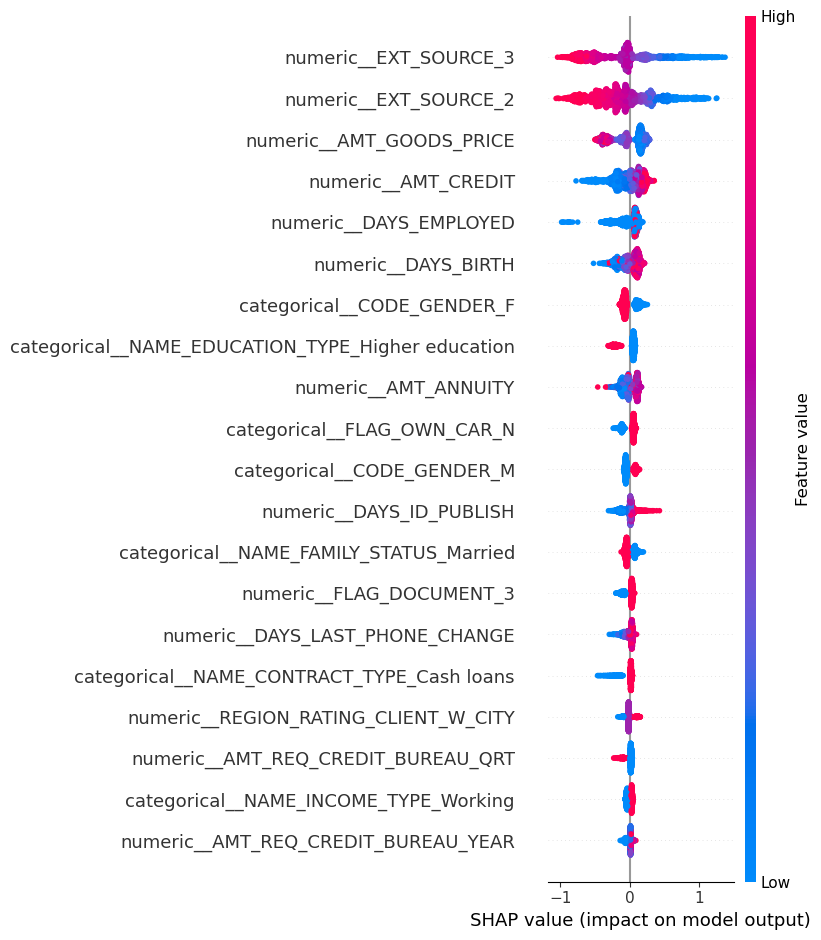

In [118]:
shap.summary_plot(
    shap_values,
    X_shap_transformed,
    feature_names=feature_names,
    max_display=20,
    show=True
)

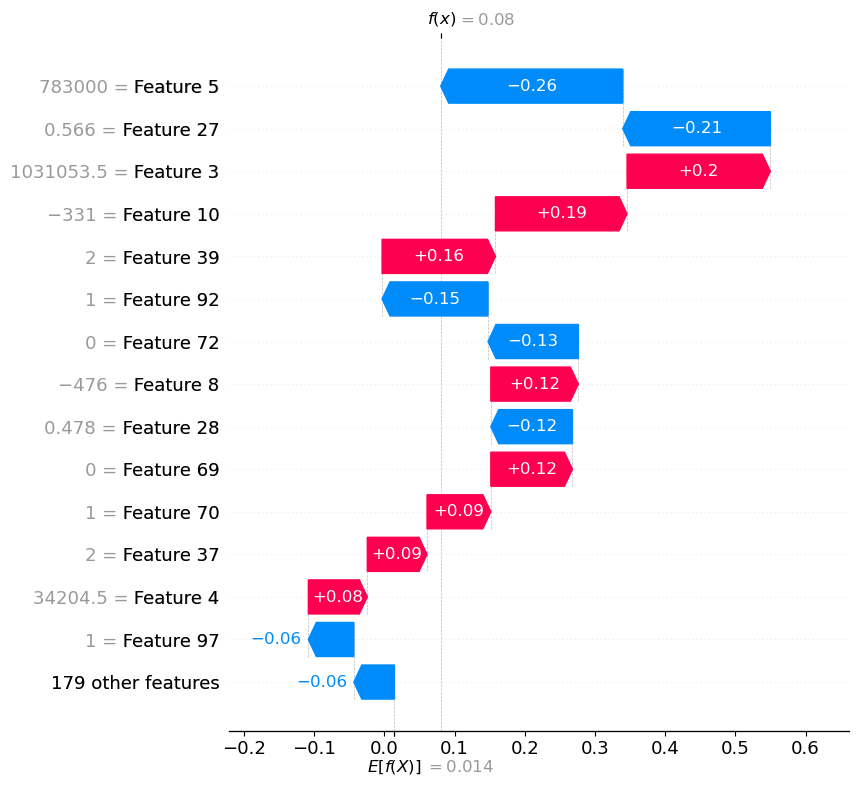

In [119]:
# Explain one sample prediction
sample_index = 0
shap.waterfall_plot(
    shap_values[sample_index],
    max_display=15
)

In [120]:
%pip install evidently

   ---------------------------------------- 0.0/11.7 MB ? eta -:--:--
    --------------------------------------- 0.3/11.7 MB ? eta -:--:--
   -- ------------------------------------- 0.8/11.7 MB 1.9 MB/s eta 0:00:06
   ---- ----------------------------------- 1.3/11.7 MB 2.1 MB/s eta 0:00:05
   ----- ---------------------------------- 1.6/11.7 MB 2.1 MB/s eta 0:00:05
   ------- -------------------------------- 2.1/11.7 MB 2.0 MB/s eta 0:00:05
   -------- ------------------------------- 2.4/11.7 MB 2.1 MB/s eta 0:00:05
   --------- ------------------------------ 2.9/11.7 MB 1.9 MB/s eta 0:00:05
   ---------- ----------------------------- 3.1/11.7 MB 1.9 MB/s eta 0:00:05
   ----------- ---------------------------- 3.4/11.7 MB 1.9 MB/s eta 0:00:05
   ------------ --------------------------- 3.7/11.7 MB 1.9 MB/s eta 0:00:05
   -------------- ------------------------- 4.2/11.7 MB 1.8 MB/s eta 0:00:05
   --------------- ------------------------ 4.5/11.7 MB 1.8 MB/s eta 0:00:05
   ----------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [121]:
import evidently
print("Evidently version:", evidently.__version__)

Evidently version: 0.7.23


In [122]:
# Select numerical features for drift monitoring
drift_features = numeric_cols[:10]
reference_data = X_train[drift_features].copy()
current_data = X_test[drift_features].copy()
print("Reference data shape:", reference_data.shape)
print("Current data shape:", current_data.shape)
print("Features monitored:", drift_features)

Reference data shape: (246008, 10)
Current data shape: (61503, 10)
Features monitored: ['SK_ID_CURR', 'CNT_CHILDREN', 'AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE', 'REGION_POPULATION_RELATIVE', 'DAYS_BIRTH', 'DAYS_EMPLOYED', 'DAYS_REGISTRATION']


In [123]:
from evidently import Report
from evidently.presets import DataDriftPreset
drift_report = Report(
    metrics=[
        DataDriftPreset()
    ]
)
drift_result = drift_report.run(
    reference_data=reference_data,
    current_data=current_data
)
print("Drift analysis completed successfully!")

Drift analysis completed successfully!


In [126]:
from pathlib import Path
Path("../REPORTS").mkdir(exist_ok=True)
drift_result.save_html("../REPORTS/data_drift_report.html")
print("Drift report saved successfully!")

Drift report saved successfully!


In [127]:
import joblib
from pathlib import Path
# MODEL folder ensure karo
Path("../MODEL").mkdir(exist_ok=True)
# Save final model
joblib.dump(final_model, "../MODEL/final_model.pkl")
print("Final model saved successfully!")

Final model saved successfully!


In [128]:
%pip install fastapi uvicorn


   ---------------------------------------- 0/4 [opentelemetry-api]
   ---------------------------------------- 0/4 [opentelemetry-api]
   -------------------- ------------------- 2/4 [starlette]
   -------------------- ------------------- 2/4 [starlette]
   -------------------- ------------------- 2/4 [starlette]
   -------------------- ------------------- 2/4 [starlette]
   ------------------------------ --------- 3/4 [fastapi]
   ------------------------------ --------- 3/4 [fastapi]
   ------------------------------ --------- 3/4 [fastapi]
   ------------------------------ --------- 3/4 [fastapi]
   ------------------------------ --------- 3/4 [fastapi]
   ------------------------------ --------- 3/4 [fastapi]
   ---------------------------------------- 4/4 [fastapi]

Note: you may need to restart the kernel to use updated packages.


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [129]:
import fastapi
import uvicorn
print("FastAPI version:", fastapi.__version__)
print("Uvicorn installed successfully!")

FastAPI version: 0.142.2
Uvicorn installed successfully!
